# Предсказание подписки на срочный депозит: Bank Marketing (UCI, id=222)
**Автор:** Левин И. · Практикум УрФУ · итоговый отчёт по индивидуальной части проекта

## Краткое резюме

**Задача.** По данным телемаркетинга португальского банка (45 211 звонков, 2008–2010) предсказать, согласится ли клиент оформить срочный депозит. Доля согласившихся 11,7%.

**Что получилось.**
- Финальная модель: градиентный бустинг LightGBM (мелкие деревья, параметры подобраны Optuna) на 23 признаках, без `duration`, без признаков периода и без `campaign`, с историей клиента на момент звонка.
- **Честное качество на отложенной выборке** (обучение до 2009-05, проверка на 2009-06 … 2010-11): **ROC-AUC = 0,60** (95% доверительный интервал 0,58–0,61), **Lift@10% = 1,46** (1,37–1,55). Среди 10% клиентов с наивысшей оценкой модели доля согласившихся 67%, при средней по выборке 45,5%.
- Модель слабая: ранжирует лучше случайного, но ненамного. На клиентах с историей AUC 0,66, на «холодных» клиентах (без истории) 0,51, то есть там модель не лучше случайности.

**Главные выводы работы.**
1. `duration` (длительность разговора) даёт AUC 0,89–0,91 и **не может использоваться**: известна только после звонка. Это утечка.
2. Случайная кросс-валидация завышает качество: для набора с признаками периода она даёт AUC 0,72, а проверка по блокам и по времени 0,57–0,58; даже без этих признаков случайная проверка выше (0,62 против 0,57 по времени). Причина — сильный временной дрейф: конверсия растёт с 5% до 52%.
3. Не помогло: инженерные признаки, балансировка классов (все варианты портят калибровку вероятностей, а ранжирование не улучшают), учёт клиентов при разбиении, усложнение модели: простая логистическая регрессия на тех же признаках на hold-out не хуже бустинга (AUC 0,61 против 0,60).
4. Помогло: подбор гиперпараметров (мелкие деревья и сильная регуляризация: +0,008 AUC на hold-out), дообучение на свежих данных (+0,02 AUC), калибровка вероятностей (корректирует шкалу, но не ранжирование).
5. Практически: надёжный сигнал даёт только то, что банк уже знает о клиенте (итог прошлой кампании и число прошлых покупок). Для «холодного» обзвона нужны другие данные.

## Как устроен отчёт
| раздел | о чём | зачем |
|---|---|---|
| 1 | Разведочный анализ данных (EDA) | понять, что за данные, где в них ловушки |
| 2 | Повторяющиеся клиенты | выяснить, правда ли «одна строка = один клиент» |
| 3 | Предобработка, инженерия признаков, схема разбиения | превратить выводы EDA в признаки и честную схему проверки |
| 4 | Проверка гипотез | экспериментально обосновать каждое решение из раздела 3 |
| 5 | Сравнение моделей и кросс-валидация | выбрать семейство моделей |
| 6 | Подбор гиперпараметров (Optuna) | настроить выбранную модель, не трогая тест |
| 7 | Финальная модель и оценка на hold-out | честная итоговая оценка, ошибки, порог, стоимость |
| 8 | Итоги, ограничения, рекомендации | что можно утверждать и что нельзя |

**Принцип, которому подчинён весь отчёт.** В данных есть сильный временной дрейф (конверсия 5% → 17% → 52% по годам), поэтому «обычная» случайная кросс-валидация даёт завышенные оценки. Все решения здесь принимаются по схемам, которые учитывают время, а финальное число получено на отложенной выборке, к которой мы не прикасались при выборе признаков и параметров.

## 0. Подготовка
Ноутбук **автономный**: все вспомогательные функции определены в нём самом, внешних файлов не нужно (кроме доступа в интернет: данные скачиваются с репозитория UCI через `ucimlrepo`).

Нужные пакеты: `numpy`, `pandas`, `matplotlib`, `seaborn`, `scipy`, `scikit-learn`, `lightgbm`, `xgboost`, `catboost`, `imbalanced-learn`, `optuna`, `ucimlrepo`. Если чего-то не хватает, раскомментируйте и выполните следующую ячейку.

In [1]:
# %pip install numpy pandas matplotlib seaborn scipy scikit-learn lightgbm xgboost catboost imbalanced-learn optuna ucimlrepo

In [2]:
import warnings; warnings.filterwarnings('ignore')
import time
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import optuna
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score, precision_recall_curve, brier_score_loss
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from imblearn.over_sampling import RandomOverSampler, SMOTENC
from imblearn.under_sampling import RandomUnderSampler

SEED = 42; N_JOBS = 8
sns.set_theme(style='whitegrid', font_scale=0.95); pd.set_option('display.width', 150, 'display.max_columns', 40)
optuna.logging.set_verbosity(optuna.logging.WARNING)

### Вспомогательные функции
Здесь собраны функции, которые используются дальше: загрузка данных, построение признаков, восстановление клиентов и истории, схемы валидации, расчёт метрик по фолдам. Читать эту ячейку необязательно: смысл каждой функции объясняется в разделе, где она применяется.

| функция | что делает | где используется |
|---|---|---|
| `load` | загружает данные, строит таргет, год и период звонка | раздел 1 |
| `build`, `final_features` | строят признаки (раздел 3) | разделы 3–7 |
| `with_dates`, `link_clients`, `history_features`, `client_groups` | восстанавливают клиентов и их историю | разделы 2–3 |
| `strat_splits`, `block_splits`, `time_splits` | три схемы валидации | разделы 4–6 |
| `run_cv`, `lift_at` | кросс-валидация и метрики по фолдам | разделы 4–6 |

In [3]:
from collections import defaultdict
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold, GroupKFold, TimeSeriesSplit
from ucimlrepo import fetch_ucirepo

MONTHS = {m: i + 1 for i, m in enumerate('jan feb mar apr may jun jul aug sep oct nov dec'.split())}
CATS = ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']


def load():
    """Сырая таблица, таргет, год (из порядка строк) и период 'год-месяц'."""
    bm = fetch_ucirepo(id=222)
    raw = pd.concat([bm.data.features, bm.data.targets], axis=1)
    y = (raw.y == 'yes').astype(int).values
    mnum = raw.month.map(MONTHS)
    year = 2008 + (mnum.diff().fillna(0) < 0).cumsum().values
    return raw, y, year, (year * 100 + mnum.values)


def build(raw, year=None, fe=True, duration=False, drop=()):
    """Признаки, считаются построчно (без таргета). Пропуски -> осмысленные категории."""
    d = raw.drop(columns='y').rename(columns={'day_of_week': 'day'}).copy()
    for c in CATS: d[c] = d[c].fillna('no_prev' if c == 'poutcome' else 'unknown')
    if fe:
        d['month_num'] = d.month.map(MONTHS)
        d['prev_contacted'] = (d.pdays != -1).astype(int)
        d['pdays_clean'] = d.pdays.where(d.pdays > 0)
        d['prev_success'] = (d.poutcome == 'success').astype(int)
        d['contact_unknown'] = (d.contact == 'unknown').astype(int)
        d['age_bin'] = pd.cut(d.age, [0, 25, 30, 40, 50, 60, 120], labels=['<=25', '26-30', '31-40', '41-50', '51-60', '60+']).astype(str)
        d['balance_log'] = np.sign(d.balance) * np.log1p(d.balance.abs())
        d['balance_neg'] = (d.balance < 0).astype(int)
        d['n_loans'] = (d.housing == 'yes').astype(int) + (d.loan == 'yes') + (d.default == 'yes')
        d['campaign_clip'] = d.campaign.clip(upper=10)
        d['previous_clip'] = d.previous.clip(upper=10)
        d['job_sr'] = d.job.isin(['student', 'retired']).astype(int)
        d = d.drop(columns='pdays')
    if year is not None: d['year'] = year
    if not duration: d = d.drop(columns='duration')
    d = d.drop(columns=list(drop))
    for c in [*CATS, 'age_bin']:
        if c in d: d[c] = d[c].astype('category')
    return d.reset_index(drop=True)


NP_DROP = ['month', 'month_num', 'day', 'contact_unknown', 'contact']   # прокси периода (обоснование в разделе 4, гипотеза H2)




# ---------- схемы валидации: каждая возвращает список (train_idx, test_idx) ----------
def strat_splits(y, groups=None, k=5):
    """Stratified K-fold; с groups — StratifiedGroupKFold (один клиент целиком в одном фолде)."""
    if groups is None: return list(StratifiedKFold(k, shuffle=True, random_state=SEED).split(y, y))
    return list(StratifiedGroupKFold(k, shuffle=True, random_state=SEED).split(y, y, groups))


def block_splits(period, y, groups=None, k=5):
    """GroupKFold по периодам 'год-месяц'; с groups — убираем из train клиентов, которые есть в test (purge)."""
    sp = list(GroupKFold(k).split(y, y, period))
    if groups is None: return sp
    return [(tr[~np.isin(groups[tr], np.unique(groups[te]))], te) for tr, te in sp]


def time_splits(n, k=5):
    """Forward-chaining: учимся на прошлом, тестируем на будущем (строки идут хронологически)."""
    return list(TimeSeriesSplit(k).split(np.arange(n)))


# ---------- метрики ----------
def lift_at(y_true, p, frac=0.10):
    k = int(len(y_true) * frac)
    return y_true[np.argsort(-p)[:k]].mean() / y_true.mean()


def run_cv(make, X, y, splits):
    """Метрики по фолдам + out-of-fold предсказания и номера фолдов."""
    oof, fold, rows = np.full(len(y), np.nan), np.full(len(y), -1), []
    for i, (tr, te) in enumerate(splits):
        p = make(X).fit(X.iloc[tr], y[tr]).predict_proba(X.iloc[te])[:, 1]
        oof[te], fold[te] = p, i
        rows.append((roc_auc_score(y[te], p), average_precision_score(y[te], p), lift_at(y[te], p)))
    return pd.DataFrame(rows, columns=['auc', 'pr', 'lift10']), oof, fold


# ---------- восстановление клиентов и история на момент решения ----------
def with_dates(raw, year):
    """Копия raw с датой звонка (год восстановлен по порядку строк) и без NaN в job/education."""
    d = raw.copy()
    d['date'] = pd.to_datetime(dict(year=year, month=raw.month.map(MONTHS), day=raw.day_of_week))
    for c in ['job', 'education']: d[c] = d[c].fillna('unknown')
    return d


def link_clients(d):
    """Для строки с pdays>0 ищем прошлую запись того же клиента: дата = date - pdays, тот же профиль,
    проверка campaign_old + previous_old == previous_new. Возвращает индекс прошлой записи (-1 если нет)."""
    keys = defaultdict(list)
    for i, k in enumerate(zip(d.date, d.job, d.marital, d.education, d.default)): keys[k].append(i)
    prev = np.full(len(d), -1)
    for i in np.where(d.pdays.values > 0)[0]:
        gap = int(d.pdays.iat[i]); dt = d.date.iat[i] - pd.Timedelta(days=gap)
        cand = [j for j in keys.get((dt, d.job.iat[i], d.marital.iat[i], d.education.iat[i], d.default.iat[i]), [])
                if j < i and 0 <= d.age.iat[i] - d.age.iat[j] <= gap // 365 + 1]
        if not cand: continue
        ok = [j for j in cand if d.campaign.iat[j] + d.previous.iat[j] == d.previous.iat[i]]
        if len(cand) == 1: prev[i] = cand[0]
        elif len(ok) == 1: prev[i] = ok[0]
        elif len(ok) > 1: prev[i] = min(ok, key=lambda j: abs(d.balance.iat[j] - d.balance.iat[i]))
    return prev


def history_features(d, y, prev):
    """Что известно о клиенте НА МОМЕНТ звонка: идём по цепочке прошлых записей (все строго раньше по дате)."""
    n = len(d); dt = d.date.values; rows = []
    for i in range(n):
        j = prev[i]; depth = nb = 0; last_buy = np.nan
        while j >= 0:
            depth += 1; nb += y[j]
            if y[j] == 1 and np.isnan(last_buy): last_buy = (dt[i] - dt[j]) / np.timedelta64(1, 'D')
            j = prev[j]
        rows.append((depth, nb, int(nb > 0), last_buy))
    return pd.DataFrame(rows, columns=['h_depth', 'h_n_buys', 'h_ever_bought', 'h_days_since_buy'])


def final_features(raw, year, y):
    """Финальный набор: без duration, без прокси периода, без campaign + история клиента."""
    X = build(raw, drop=NP_DROP + ['campaign', 'campaign_clip'])
    d = with_dates(raw, year)
    return pd.concat([X, history_features(d, y, link_clients(d))], axis=1)


def client_groups(prev):
    """Id клиента = компонента связности по ссылкам «запись -> прошлая запись» (для групповой валидации)."""
    n = len(prev); i = np.where(prev >= 0)[0]
    return connected_components(coo_matrix((np.ones(len(i)), (i, prev[i])), shape=(n, n)), directed=False)[1]

# 1. Разведочный анализ данных (EDA)

**Цель раздела.** Прежде чем строить признаки и модели, нужно понять: какие бывают значения, где пропуски и выбросы, как устроено время, какие признаки нельзя использовать. Это определяет всё остальное.

**Задача.** Бинарная классификация: подпишется ли клиент на срочный депозит (`y = yes`) по итогам телемаркетингового звонка португальского банка. Каждая строка описывает один контакт.

## 1.1 Загрузка и структура

In [4]:
raw, y, year, period = load(); n = len(raw)      # y: 0/1, year: год звонка (восстановлен), period: ГГГГММ
print('строк:', n, '| столбцов:', raw.shape[1])
display(raw.head(4))
display(raw.dtypes.value_counts().rename('столбцов').to_frame().T)

строк: 45211 | столбцов: 17


,age,job,marital,education,default,balance,housing,loan,contact,day_of_week,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,NaN,5,may,261,1,-1,0,NaN,no
1,44,technician,single,secondary,no,29,yes,no,NaN,5,may,151,1,-1,0,NaN,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,NaN,5,may,76,1,-1,0,NaN,no
3,47,blue-collar,married,NaN,no,1506,yes,no,NaN,5,may,92,1,-1,0,NaN,no


,str,int64
столбцов,10,7


**Описание признаков.**
- Клиент: `age`, `job`, `marital`, `education`, `default` (есть ли просрочка по кредиту), `balance` (средний годовой баланс), `housing` и `loan` (ипотека и потребительский кредит).
- Текущий контакт: `contact` (канал), `day_of_week`, `month` (когда звонили), `duration` (длительность разговора, сек), `campaign` (число звонков этой кампании этому клиенту).
- История: `pdays` (дней с прошлого контакта, −1 если не было), `previous` (число прошлых контактов), `poutcome` (итог прошлой кампании).
- Цель: `y`.

## 1.2 Оптимизация памяти
Датасет небольшой (45 тыс. строк), но привычка экономить память полезна для больших данных: текстовые столбцы с малым числом значений переводим в `category`, целые — в самый узкий целый тип.

In [5]:
def optimize(df):
    out = df.copy()
    for c in out.select_dtypes('object'): out[c] = out[c].astype('category')
    for c in out.select_dtypes('int64'): out[c] = pd.to_numeric(out[c], downcast='integer')
    return out
before = raw.memory_usage(deep=True).sum() / 2**20; after = optimize(raw).memory_usage(deep=True).sum() / 2**20
print(f'память: {before:.2f} МБ -> {after:.2f} МБ (в {before / after:.1f} раза меньше)')

память: 24.56 МБ -> 0.99 МБ (в 24.7 раза меньше)


## 1.3 Пропуски
Пропуски кодируются как `NaN`. Важно понять не сколько их, а **что они означают**: случайная потеря данных или осмысленный сигнал.

In [6]:
miss = raw.isna().sum(); miss = miss[miss > 0].to_frame('пропусков'); miss['доля'] = (miss.пропусков / n).round(3)
display(miss.T)
a, b = raw.poutcome.isna(), raw.pdays == -1
print(f'poutcome пропущен: {a.sum()} | pdays = -1: {b.sum()} | пропуск poutcome при pdays > 0: {(a & ~b).sum()} | pdays = -1 при известном poutcome: {(~a & b).sum()}')
print('pdays = -1  <=>  previous = 0 :', bool(((raw.pdays == -1) == (raw.previous == 0)).all()))

,job,education,contact,poutcome
пропусков,288.000,1857.000,13020.000,36959.000
доля,0.006,0.041,0.288,0.817


poutcome пропущен: 36959 | pdays = -1: 36954 | пропуск poutcome при pdays > 0: 5 | pdays = -1 при известном poutcome: 0
pdays = -1  <=>  previous = 0 : True


**Что видим.** `poutcome` (82% пропусков) пропущен почти ровно тогда, когда `pdays = −1` и `previous = 0` (расхождение всего в 5 строк из 45 тысяч), то есть **клиенту раньше не звонили**. Это не потеря данных, а отдельная категория «нет прошлой кампании». `job` и `education` (меньше 5%) — настоящие пропуски, заменим явной категорией `unknown`. Пропуски `contact` (29%) выглядят подозрительно, к ним вернёмся ниже.

## 1.4 Время: в данных нет даты, но она восстанавливается
В таблице нет года, а `day_of_week` на самом деле **день месяца** (значения 1–31, а не дни недели). Строки идут в хронологическом порядке: номер месяца растёт и сбрасывается при переходе года. По этим сбросам мы восстанавливаем год (2008, 2009, 2010). Это важно: данные охватывают три года, и условия за это время сильно менялись.

значения day_of_week: 1 … 31 (это день месяца)


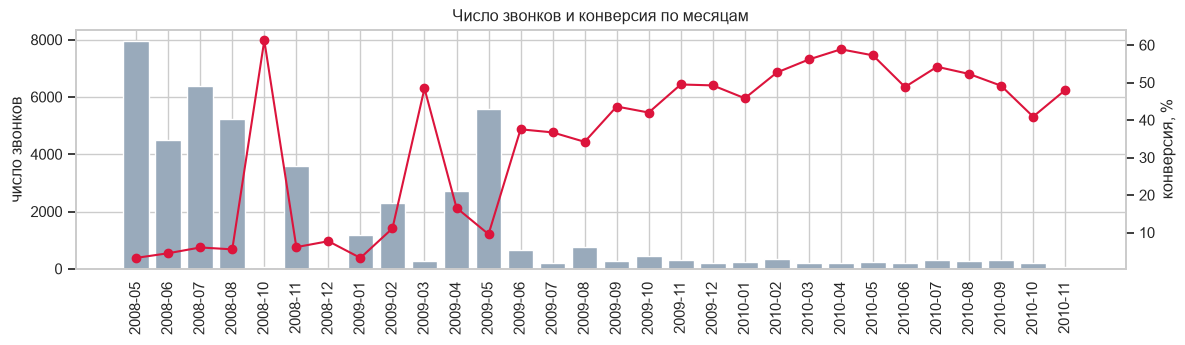

год,2008,2009,2010
звонков,27729.000,14862.000,2620.000
месяцев,7.000,12.000,11.000
конверсия,0.051,0.171,0.516
звонков в месяц,3961.000,1238.000,238.000


In [7]:
print('значения day_of_week:', raw.day_of_week.min(), '…', raw.day_of_week.max(), '(это день месяца)')
per = pd.DataFrame({'период': pd.to_datetime(pd.Series(period).astype(str), format='%Y%m').dt.strftime('%Y-%m'), 'y': y})
m = per.groupby('период').y.agg(['size', 'mean'])
fig, ax = plt.subplots(figsize=(12, 3.6)); ax.bar(m.index, m['size'], color='#9ab', label='число звонков'); ax.set_ylabel('число звонков')
ax2 = ax.twinx(); ax2.plot(m.index, m['mean'] * 100, 'o-', color='crimson', label='конверсия, %'); ax2.set_ylabel('конверсия, %'); ax2.grid(False)
ax.tick_params(axis='x', rotation=90); ax.set_title('Число звонков и конверсия по месяцам'); plt.tight_layout(); plt.show()
yr = pd.DataFrame({'год': year, 'y': y, 'период': period}).groupby('год').agg(звонков=('y', 'size'), месяцев=('период', 'nunique'), конверсия=('y', 'mean'))
yr['звонков в месяц'] = (yr.звонков / yr.месяцев).round(0); display(yr.round(3).T)

**Вывод.** Конверсия растёт с 5% (2008) до 17% (2009) и 52% (2010), а число звонков в месяц падает с ≈4000 до ≈240. Меняется сам режим обзвона: массовые звонки сменяются точечными. Это главный факт о данных: **любая модель, обученная на одном периоде, работает на другом хуже**, и случайная перемешивающая кросс-валидация эту проблему скрывает (проверим в разделе 4).

## 1.5 Пропуски `contact` — это маркер периода
Пропуск в `contact` выглядит как «канал неизвестен». Проверим, как он связан с годом.

In [8]:
cn = pd.DataFrame({'год': year, 'contact пропущен': raw.contact.isna().values, 'y': y})
display(cn.groupby('год').agg(доля_пропусков=('contact пропущен', 'mean'), конверсия=('y', 'mean')).round(3).T)
per_nan = pd.DataFrame({'период': per['период'], 'nan': raw.contact.isna().values}).groupby('период').nan.mean()
print('периоды, где contact пропущен у 100% строк:', list(per_nan[per_nan == 1].index))

год,2008,2009,2010
доля_пропусков,0.460,0.000,0.096
конверсия,0.051,0.171,0.516


периоды, где contact пропущен у 100% строк: ['2008-05', '2008-06']


**Вывод.** 98% пропусков `contact` относятся к 2008 году (май–июнь 2008 пропущены у 100% строк). Значит, пропуск — не свойство клиента, а **метка периода**, когда канал не фиксировали. Модель, видящая такой признак, начнёт «угадывать» период, а не клиента. Это ещё одна причина исключить `contact`.

## 1.6 Таргет и признаки: конверсия по группам
Базовая конверсия 11,7% (класс «yes» редкий, дисбаланс примерно 1:7,5). Посмотрим на конверсию по категориальным признакам: так видно, какие группы отличаются от среднего (анализ признаков через призму целевого класса).

доля yes: 0.117  (yes: 5289, no: 39922, соотношение 1:7.5)


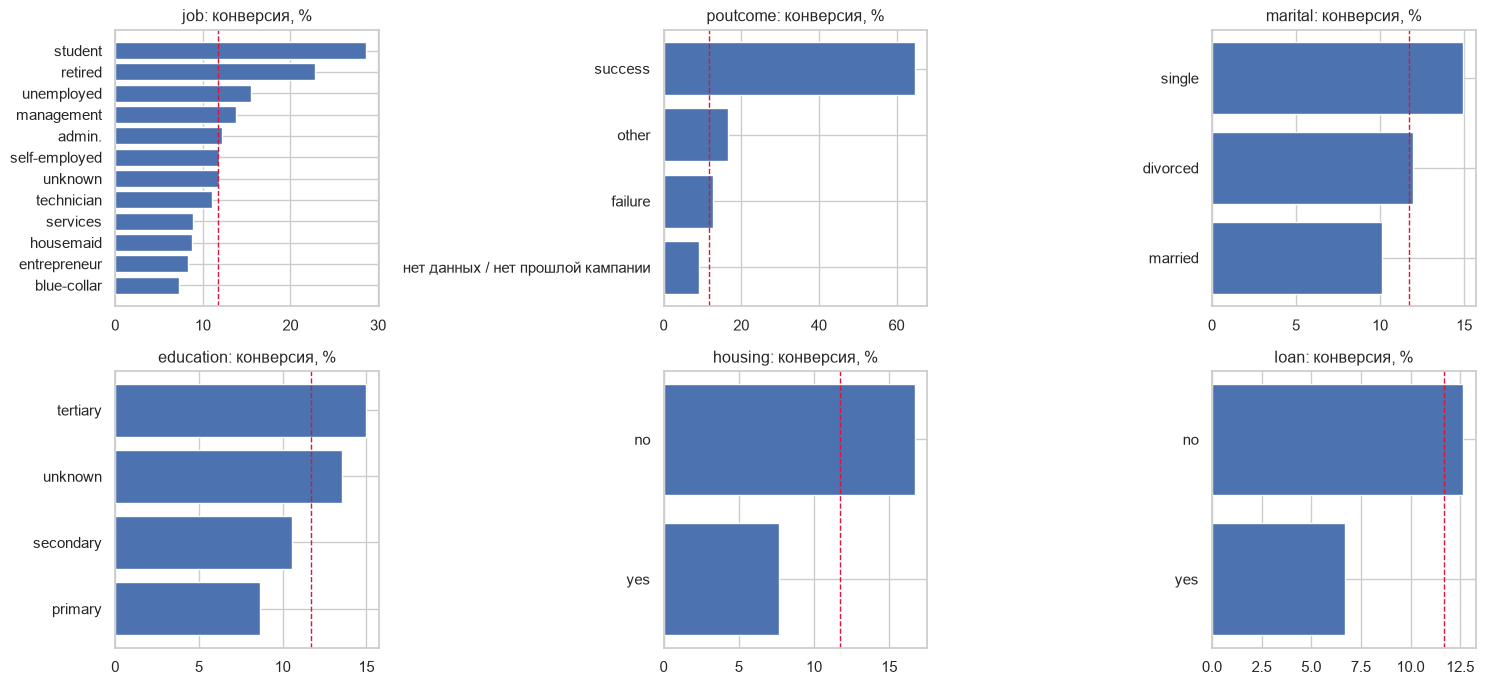

In [9]:
print(f'доля yes: {y.mean():.3f}  (yes: {y.sum()}, no: {(1 - y).sum()}, соотношение 1:{(1 - y.mean()) / y.mean():.1f})')
d0 = raw.copy(); d0['y01'] = y
for c in ['job', 'education', 'poutcome']: d0[c] = d0[c].fillna('нет данных / нет прошлой кампании' if c == 'poutcome' else 'unknown')
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, c in zip(axes.ravel(), ['job', 'poutcome', 'marital', 'education', 'housing', 'loan']):
    g = d0.groupby(c).y01.agg(['mean', 'size']).sort_values('mean'); ax.barh(g.index.astype(str), g['mean'] * 100, color='#4c72b0')
    ax.axvline(y.mean() * 100, color='crimson', ls='--', lw=1); ax.set_title(f'{c}: конверсия, %')
plt.tight_layout(); plt.show()

**Что видим** (красная линия — средняя конверсия 11,7%).
- Сильнее всего выделяется `poutcome`: после **успешной** прошлой кампании клиенты соглашаются в ≈65% случаев.
- Выше среднего у студентов и пенсионеров, ниже у рабочих (`blue-collar`) и предпринимателей.
- Клиенты с ипотекой (`housing = yes`) соглашаются заметно реже: вероятно, у них меньше свободных денег.
- Эти различия — гипотезы о том, какие признаки полезны, их мы проверим моделью.

## 1.7 Числовые признаки и выбросы

,min,1%,50%,99%,max
age,18.0,23.0,39.0,71.0,95.0
balance,-8019.0,-627.0,448.0,13164.9,102127.0
duration,0.0,11.0,180.0,1269.0,4918.0
campaign,1.0,1.0,2.0,16.0,63.0
pdays,-1.0,-1.0,-1.0,370.0,871.0
previous,0.0,0.0,0.0,8.9,275.0


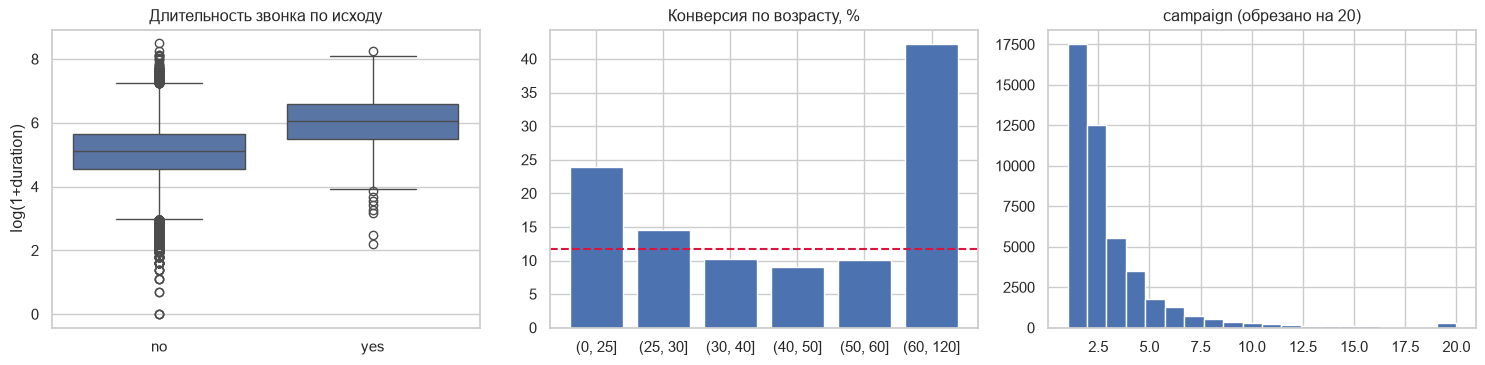

медиана duration, сек:  no = 164  yes = 426


In [10]:
num = raw[['age', 'balance', 'duration', 'campaign', 'pdays', 'previous']]
q = num.describe(percentiles=[.01, .5, .99]).T[['min', '1%', '50%', '99%', 'max']]; display(q.round(1))
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
sns.boxplot(x=y, y=np.log1p(raw.duration), ax=ax[0]); ax[0].set(xticklabels=['no', 'yes'], xlabel='', ylabel='log(1+duration)', title='Длительность звонка по исходу')
g = d0.assign(age_bin=pd.cut(d0.age, [0, 25, 30, 40, 50, 60, 120])).groupby('age_bin', observed=True).y01.mean() * 100
ax[1].bar(g.index.astype(str), g.values, color='#4c72b0'); ax[1].set(title='Конверсия по возрасту, %'); ax[1].axhline(y.mean() * 100, color='crimson', ls='--')
ax[2].hist(np.clip(raw.campaign, 0, 20), bins=20, color='#4c72b0'); ax[2].set(title='campaign (обрезано на 20)')
plt.tight_layout(); plt.show()
print('медиана duration, сек:  no =', int(raw.duration[y == 0].median()), ' yes =', int(raw.duration[y == 1].median()))

**Что видим.**
- `balance`: есть отрицательные значения и экстремальные выбросы (максимум в сотни тысяч при медиане ≈450). Для линейных моделей это проблема, для деревьев нет. Для устойчивости добавим логарифм со знаком.
- `campaign` и `previous`: длинные хвосты (до 63 и 275 контактов). Возможны ошибки ввода, но это и редкие реальные случаи; обрезаем на 10 для устойчивости.
- `age`: U-образная зависимость: конверсия выше у молодых (≤25) и пожилых (60+), чем в середине. Деревья ловят нелинейность сами, но «возрастные корзины» дадут простую интерпретацию.
- `duration`: у согласившихся разговор в разы длиннее. Это не «признак клиента», а следствие исхода (разговор идёт долго, потому что клиент заинтересован). Об этом подробнее ниже.

## 1.8 Главные выводы EDA
| находка | вывод для моделирования |
|---|---|
| `day_of_week` — на самом деле день месяца, год в данных отсутствует, но восстанавливается | строим время и валидируем по времени |
| Конверсия 5% → 17% → 52% по годам, режим обзвона меняется | случайная кросс-валидация завышает качество; нужна проверка «обучились на прошлом, проверили на будущем» |
| `contact` пропущен в основном в 2008 (маркер периода) | `contact`, `month`, `day` — прокси периода, их нужно проверить и, вероятно, убрать |
| `poutcome` пропущен ≈ нет прошлых контактов (82%, расхождение в 5 строках) | это категория «нет истории», а не потеря данных |
| `duration` у «yes» кратно больше | признак известен только после звонка: **утечка**, не использовать для предсказания |
| `campaign` включает последний звонок, по итогу которого принято решение | формально «из будущего», нужно проверить вклад |
| Дисбаланс 1:7,5 | метрики PR-AUC, Lift, а не точность (accuracy); проверим способы балансировки |
| Возможны повторные клиенты (в данных нет id) | проверим в разделе 2 |

**Итог раздела 1.** Данные устроены сложнее, чем выглядят: нет даты и идентификатора клиента, часть «пропусков» несёт смысл, а один из признаков (`duration`) недоступен на момент предсказания. Главный практический вывод: **качество модели нельзя оценивать на случайных фолдах**, нужна проверка по времени. Это определяет всю дальнейшую работу.

# 2. Повторяющиеся клиенты

**Вопрос.** В датасете нет идентификатора клиента. Правда ли, что одна строка — один клиент? Если нет, возникают две проблемы: (1) при случайном разбиении один и тот же человек может попасть и в обучение, и в тест, и мы завысим качество; (2) у повторных клиентов есть **история**, которую можно использовать как признак.

**Идея восстановления.** Если у строки `pdays = N`, то прошлый контакт был ровно за N дней до неё. Ищем более раннюю запись на эту дату с тем же профилем (`job`, `marital`, `education`, `default`, возраст не мог вырасти больше чем на число прошедших лет + 1). Для проверки, что связка верная, используем не таргет, а число контактов: у ранней записи `campaign + previous` (все её контакты) должно равняться `previous` поздней.

In [11]:
d = with_dates(raw, year); d['y01'] = y
prev = link_clients(d)                         # индекс прошлой записи клиента или -1
linked = prev >= 0
print('строк с историей (pdays > 0):', int((d.pdays > 0).sum()), '| из них удалось связать с прошлой записью:', int(linked.sum()),
      f'({linked.sum() / (d.pdays > 0).sum():.0%})')
# независимая проверка (таргет не использовался при поиске): итог прошлой кампании в poutcome новой записи должен совпадать с y старой записи
chk = pd.crosstab(d.poutcome[linked].fillna('NaN').values, d.y01.values[prev[linked]], rownames=['poutcome (новая запись)'], colnames=['y (старая запись)'])
display(chk)
print('корреляция balance старой и новой записи:', np.corrcoef(d.balance[linked], d.balance.values[prev[linked]])[0, 1].round(2))
client = client_groups(prev); sizes = pd.Series(client).value_counts()
print(f'клиентов (групп): {len(sizes)} на {n} строк; строк у клиентов с 2+ записями: {sizes[sizes > 1].sum()} ({sizes[sizes > 1].sum() / n:.0%})')

строк с историей (pdays > 0): 8257 | из них удалось связать с прошлой записью: 7023 (85%)


y (старая запись),0,1
poutcome (новая запись),,
failure,4901,0
other,573,38
success,1,1510


корреляция balance старой и новой записи: 0.95
клиентов (групп): 38188 на 45211 строк; строк у клиентов с 2+ записями: 12769 (28%)


**Проверка качества связок.** Раз мы искали связи без таргета, а `poutcome` новой записи (`success` / `failure`) почти идеально совпадает с исходом старой записи (`yes` / `no`), связи надёжны. Баланс старой и новой записи сильно коррелирует. Часть записей с историей связать не удалось (профиль изменился или прошлый контакт вне датасета): мы теряем часть истории, но не создаём ложных связей.

**Что это даёт.**
1. Около четверти строк принадлежит клиентам с несколькими записями: при валидации это надо учитывать (проверим влияние в разделе 4).
2. Для каждой записи можно честно посчитать **историю на момент звонка**: сколько раз клиент уже покупал, когда в последний раз и т. д. Все эти данные уже известны банку в момент решения «звонить ли».

**Итог раздела 2.** Из 8 257 строк с историей связать с прошлой записью удалось 7 023 (85%); итог прошлой кампании в `poutcome` совпал с исходом старой записи почти идеально (1 510 из 1 511 «success» связаны с «yes»), корреляция баланса 0,95. Около 28% всех строк принадлежат клиентам с несколькими записями. Связки приблизительные (профиль клиента, а не настоящий идентификатор), но проверка без использования таргета показывает, что ложных связей немного.

# 3. Предобработка, инженерия признаков, схема разбиения

## 3.1 Что делаем с каждым признаком и почему
| признак | решение | причина |
|---|---|---|
| `duration` | **удалить** | известен только после звонка (утечка), проверка в H1 |
| `month`, `day_of_week`, `contact` | **удалить** | метки периода: модель запоминает «когда» вместо «кто», проверка в H2 |
| `campaign` | **удалить** | включает последний звонок, формально «из будущего»; вклад мал, проверка в H4 |
| `pdays` | заменить на `pdays_clean` | значение −1 («не звонили») — это не число дней; заменяем на `NaN`, а факт отсутствия истории кодируют `prev_contacted` и `poutcome` |
| `poutcome` (NaN) | категория `no_prev` | пропуск — это «нет прошлой кампании», а не потеря |
| `job`, `education`, `marital`... (NaN) | категория `unknown` | деревья отдельно используют «неизвестно» |
| `balance` | добавить `balance_log` (логарифм со знаком) и `balance_neg` (флаг долга) | экстремальные выбросы, у отрицательного баланса своя логика |
| `age` | добавить `age_bin` | нелинейная (U-образная) зависимость |
| `previous` | добавить `previous_clip` (обрезка на 10) | длинный хвост |
| `housing`, `loan`, `default` | добавить `n_loans` (сколько обязательств) | общая «закредитованность» клиента |
| `job` | добавить `job_sr` (студент/пенсионер) | эти группы с повышенной конверсией (EDA) |
| `poutcome` | добавить `prev_success` | самый сильный сигнал, делаем явным флагом |
| история клиента (раздел 2) | добавить `h_n_buys`, `h_ever_bought`, `h_days_since_buy`, `h_depth` | известно на момент звонка, проверка в H5 |

**Категориальные признаки** передаём в LightGBM как тип `category`. Он не нуждается в one-hot кодировании: для каждого признака сортирует категории по статистике градиентов и ищет лучшее разбиение (по смыслу это сглаженный target encoding, вычисляемый только на обучающей части, поэтому утечки таргета нет). Для линейной модели и случайного леса используем one-hot и стандартизацию.

In [12]:
X = final_features(raw, year, y)        # финальный набор: без duration, без прокси периода, без campaign, + история клиента
print('признаков:', X.shape[1])
display(X.head(3).T.rename(columns=lambda c: f'строка {c}'))

признаков: 23


,строка 0,строка 1,строка 2
age,58,44,33
job,management,technician,entrepreneur
marital,married,single,married
education,tertiary,secondary,secondary
default,no,no,no
balance,2143,29,2
housing,yes,yes,yes
loan,no,no,yes
previous,0,0,0
poutcome,no_prev,no_prev,no_prev


## 3.2 Схема разбиения: почему именно такая
Все схемы валидации в этом отчёте:

| схема | как устроена | что показывает |
|---|---|---|
| **strat** | случайные фолды с сохранением доли «yes» (`StratifiedKFold`) | «школьная» оценка; стратификация нужна из-за дисбаланса, но она ничего не знает о времени |
| **block** | фолды по целым месяцам (`GroupKFold` по году-месяцу): в тест уходят месяцы, которых модель не видела | обобщение на новые периоды |
| **time** | forward-chaining (`TimeSeriesSplit`): учимся на прошлом, тестируем на следующем куске | ближе всего к боевому сценарию |
| **hold-out** | одна отложенная выборка: всё после 2009-05 | финальная честная оценка |

**Финальный hold-out.** Данные делятся на два режима обзвона: *до 2009-05* (массовые звонки, много контактов, конверсия 7%) и *после* (точечные звонки, мало контактов, конверсия 45%). Мы обучаемся на первом и проверяем на втором. Это самая жёсткая проверка: модель должна пережить смену режима. Все решения (признаки, гипотезы, подбор параметров) принимаются **только по train**, hold-out открывается один раз в разделе 7.

In [13]:
cut = int(np.argmax(period >= 200906)); tr = np.arange(cut); te = np.arange(cut, n)
ytr, yte = y[tr], y[te]; ptr = period[tr]
print(f'train: {len(tr)} строк, 2008-05 … 2009-05, конверсия {ytr.mean():.1%}')
print(f'hold-out: {len(te)} строк, 2009-06 … 2010-11, конверсия {yte.mean():.1%}')
hist_flag = (X.h_depth > 0).values
print(f'доля клиентов с историей: train {hist_flag[tr].mean():.1%} -> hold-out {hist_flag[te].mean():.1%} (режим действительно другой)')

train: 39752 строк, 2008-05 … 2009-05, конверсия 7.1%
hold-out: 5459 строк, 2009-06 … 2010-11, конверсия 45.5%
доля клиентов с историей: train 11.4% -> hold-out 45.6% (режим действительно другой)


Для проверки гипотез используем один и тот же «базовый» LightGBM с умеренными параметрами (не подобранными, чтобы эксперименты не зависели от настройки): так разница между вариантами объясняется признаками, а не параметрами.

In [14]:
BASE = dict(n_estimators=300, learning_rate=0.05, num_leaves=15, min_child_samples=50, colsample_bytree=0.8, subsample=0.8, subsample_freq=1, reg_lambda=1)
def mk(F=None, **p): return LGBMClassifier(**{**BASE, **p}, n_jobs=N_JOBS, random_state=SEED, verbose=-1)

# наборы признаков для гипотез
base_nh = build(raw, drop=NP_DROP + ['campaign', 'campaign_clip'])          # финальный набор без истории клиента
sets = {'final': X, 'no_history': base_nh}

def schemes(groups=None):
    # три схемы валидации, построенные только на train
    return {'strat': strat_splits(ytr, None if groups is None else groups[tr]),
            'block': block_splits(ptr, ytr, None if groups is None else groups[tr]),
            'time': time_splits(len(tr))}
SP = schemes()

def cv_table(feature_sets, which=('strat', 'block', 'time'), make=mk, sp=None):
    # средние метрики по фолдам для каждого набора признаков и схемы
    sp = sp or SP; rows = []
    for name, F in feature_sets.items():
        Ft = F.iloc[tr].reset_index(drop=True)
        r = {'вариант': name}
        for s in which:
            m = run_cv(make, Ft, ytr, sp[s])[0]; r[f'{s} AUC'] = m.auc.mean(); r[f'{s} PR'] = m.pr.mean(); r[f'{s} Lift@10%'] = m.lift10.mean()
        rows.append(r)
    return pd.DataFrame(rows).set_index('вариант')

# 4. Проверка гипотез
Каждое решение из раздела 3 формулируем как гипотезу и проверяем экспериментально. Метрики: **ROC-AUC** (качество ранжирования клиентов), **PR-AUC** и **Lift@10%** (во сколько раз доля «yes» среди 10% клиентов с наивысшей оценкой выше средней по выборке: прямо отвечает на вопрос «кому звонить в первую очередь»). Всё считается на train по трём схемам валидации. Разницу менее ≈0,01 AUC считаем шумом: разброс между фолдами заметно больше.

## H1. `duration` — утечка
**Гипотеза.** Длительность разговора известна только после звонка и является следствием исхода, поэтому в «боевую» модель её брать нельзя; если её добавить, метрики будут нереально высокими.
**Как проверяем.** Сравниваем модель без `duration` и с ним.

In [15]:
h1 = cv_table({'без duration': X, 'с duration': X.assign(duration=raw.duration.values)}, which=('strat', 'time'))
display(h1.round(3))

,strat AUC,strat PR,strat Lift@10%,time AUC,time PR,time Lift@10%
вариант,,,,,,
без duration,0.626,0.150,2.344,0.568,0.113,1.620
с duration,0.907,0.462,6.219,0.890,0.456,6.183


**Вывод H1: гипотеза подтверждена.** Добавление `duration` поднимает AUC с 0,63 до 0,91 при случайной проверке и с 0,57 до 0,89 при проверке по времени. Такой скачок невозможен для «честного» признака: длительность разговора определяется исходом (клиенту, которому интересно, звонят дольше). Для модели, которая должна помогать решать, кому звонить, этот признак недоступен. **Решение: `duration` исключён.** Заодно получили полезный ориентир: любой скачок качества на десятки процентов должен вызывать подозрение на утечку.

## H2. `month`, `day`, `contact` — прокси периода, они завышают случайную валидацию
**Гипотеза.** Эти признаки не описывают клиента, а выдают время звонка, а конверсия сильно зависит от периода. При случайном разбиении модель «узнаёт» период и показывает отличное качество, но на новых периодах (схемы block и time) оно упадёт.
**Как проверяем.** Модель с этими признаками и без них, по всем трём схемам.

In [16]:
with_proxy = build(raw, drop=['campaign', 'campaign_clip'])         # те же признаки, но с month, day, contact
h2 = cv_table({'без прокси периода': base_nh, 'с month / day / contact': with_proxy})
display(h2.round(3)[['strat AUC', 'block AUC', 'time AUC', 'strat Lift@10%', 'block Lift@10%', 'time Lift@10%']])

,strat AUC,block AUC,time AUC,strat Lift@10%,block Lift@10%,time Lift@10%
вариант,,,,,,
без прокси периода,0.624,0.602,0.568,2.273,1.886,1.63
с month / day / contact,0.715,0.575,0.565,3.475,1.612,1.59


**Вывод H2: гипотеза подтверждена для случайной валидации, частично для остальных.** Случайная проверка (strat) с признаками периода даёт AUC 0,715 против 0,624 без них, то есть +0,09 «из воздуха». При блочной проверке (тест на целых месяцах, которых модель не видела) признаки периода уже вредят (0,575 против 0,602), а в схеме time различия нет (0,565 против 0,568). Именно эту картину ожидали бы, если бы модель запоминала период, а не клиента. **Решение: признаки периода исключены.**

Важная оговорка: на финальной отложенной выборке эти признаки, наоборот, немного помогают (см. раздел 7.1 и диагностику), поэтому вывод «они вредят» верен не во всех схемах, и мы честно сообщаем об этом в итогах.

## H3. Инженерные признаки нужны (или нет)
**Гипотеза.** Логарифм баланса, возрастные корзины, `n_loans` и прочие производные признаки улучшат качество.
**Как проверяем.** Исходные признаки (без `duration`, прокси периода и `campaign`) против набора с инженерными признаками. Деревья часто сами выучивают такие преобразования, поэтому прироста может не быть.

In [17]:
raw_clean = build(raw, fe=False, drop=['month', 'day', 'contact', 'campaign'])     # только исходные признаки
h3 = cv_table({'только исходные': raw_clean, 'с инженерными признаками': base_nh}, which=('block', 'time'))
display(h3.round(3))

,block AUC,block PR,block Lift@10%,time AUC,time PR,time Lift@10%
вариант,,,,,,
только исходные,0.601,0.121,1.880,0.567,0.112,1.652
с инженерными признаками,0.602,0.123,1.886,0.568,0.113,1.630


**Вывод H3: инженерные признаки практически не дают эффекта** (block AUC 0,601 → 0,602, time 0,567 → 0,568). Это ожидаемо: деревья сами умеют выучивать логарифмы, пороги и взаимодействия. Признаки оставлены ради интерпретируемости (например, возрастные группы и число обязательств) и потому, что они не вредят, но на качество они не влияют.

## H4. `campaign` почти бесполезен и формально «из будущего»
**Гипотеза.** `campaign` (число звонков в этой кампании) включает последний звонок, по итогу которого принято решение. Если его вклад мал, убираем ради честности.

In [18]:
with_campaign = build(raw, drop=NP_DROP)      # финальные признаки + campaign, campaign_clip (без истории)
h4 = cv_table({'без campaign': base_nh, 'с campaign': with_campaign}, which=('strat', 'block', 'time'))
display(h4.round(3)[['strat AUC', 'block AUC', 'time AUC']])

,strat AUC,block AUC,time AUC
вариант,,,
без campaign,0.624,0.602,0.568
с campaign,0.632,0.602,0.570


**Вывод H4: гипотеза подтверждена.** `campaign` повышает AUC только при случайной проверке (+0,008), при блочной и временной разницы нет (0,602 / 0,568 против 0,602 / 0,570). Вклад в пределах шума при том, что признак формально «из будущего» (включает последний звонок). **Решение: `campaign` исключён.**

## H5. История клиента помогает
**Гипотеза.** Если клиент уже покупал, он, скорее всего, купит снова: число прошлых покупок и время с последней покупки должны улучшить ранжирование, особенно для повторных клиентов.
**Как проверяем.** Набор без истории против набора с историей; дополнительно смотрим AUC отдельно на строках, где история есть (по фолдам time split, где обоих классов достаточно).

In [19]:
def hist_auc(F, sp):
    # AUC по фолдам только на строках с историей клиента
    Ft = F.iloc[tr].reset_index(drop=True); hf = hist_flag[tr]; out = []
    for a, b in sp:
        p = mk().fit(Ft.iloc[a], ytr[a]).predict_proba(Ft.iloc[b])[:, 1]; mm = hf[b]
        if mm.sum() > 50 and 0 < ytr[b][mm].mean() < 1: out.append(roc_auc_score(ytr[b][mm], p[mm]))
    return np.mean(out)
h5 = cv_table({'без истории': base_nh, 'с историей клиента': X}, which=('block', 'time'))
h5['time AUC на строках с историей'] = [hist_auc(base_nh, SP['time']), hist_auc(X, SP['time'])]
display(h5.round(3)[['block AUC', 'time AUC', 'time AUC на строках с историей']])
conv = pd.Series(ytr).groupby(X.h_n_buys.clip(upper=3).values[tr]).agg(['mean', 'size']); conv.index = [str(int(i)) + ('+' if i >= 3 else '') for i in conv.index]
print('конверсия по числу прошлых покупок (train):'); display(conv.rename(columns={'mean': 'конверсия', 'size': 'строк'}).round(3).T)

,block AUC,time AUC,time AUC на строках с историей
вариант,,,
без истории,0.602,0.568,0.607
с историей клиента,0.601,0.568,0.603


конверсия по числу прошлых покупок (train):


,0,1,2
конверсия,0.068,0.325,0.571
строк,39410.000,335.000,7.000


**Вывод H5: на train гипотеза не подтвердилась, на hold-out подтверждается слабо.** В обучающем периоде история почти не добавляет качества (block 0,602 → 0,601, time 0,568 → 0,568). Причина видна в таблице: в train клиентов с покупкой в прошлом всего 335 с одной покупкой и 7 с двумя, поэтому признак почти не встречается. Конверсия при этом резко растёт с числом покупок (7% без покупок, 33% с одной, 57% с двумя), так что сам сигнал сильный, просто редкий. На hold-out, где история есть у 46% строк, прирост составляет +0,006 AUC (0,594 → 0,600). **Решение: признаки истории оставлены**: они логичны, известны на момент звонка и не вредят, но эффект в целом малый и в пределах разброса.

## H6. Один клиент в нескольких записях искажает случайную валидацию
**Гипотеза.** Если клиент попадает и в train, и в test, оценка завышена. Проверяем, меняются ли оценки, если клиента целиком отправлять в один фолд (`StratifiedGroupKFold`), а при блочной проверке убирать из train клиентов, которые есть в test (purge).

In [20]:
SPg = schemes(groups=client)
h6 = pd.DataFrame({
    'без учёта клиентов': {s: run_cv(mk, X.iloc[tr].reset_index(drop=True), ytr, SP[s])[0].auc.mean() for s in ('strat', 'block')},
    'клиент целиком в одном фолде': {s: run_cv(mk, X.iloc[tr].reset_index(drop=True), ytr, SPg[s])[0].auc.mean() for s in ('strat', 'block')}}).T
display(h6.round(3).rename(columns={'strat': 'strat AUC', 'block': 'block AUC'}))

,strat AUC,block AUC
без учёта клиентов,0.626,0.601
клиент целиком в одном фолде,0.627,0.600


**Вывод H6: гипотеза не подтвердилась.** Учёт клиентов при разбиении оценки практически не меняет (strat 0,626 → 0,627, block 0,601 → 0,600). Значит, повторные клиенты не искажали наши оценки: финальная модель с мелкими деревьями и сильной регуляризацией не запоминает отдельных людей. Эту проверку полезно было сделать, но менять схему валидации она не заставила.

## H7. Балансировка классов (дисбаланс 1:7,5)
**Гипотеза.** Взвешивание классов или ресэмплинг (урезание большинства, дублирование меньшинства, синтетические объекты) улучшит ранжирование.
**Как проверяем.** Все методы применяются **только к обучающей части фолда** (иначе была бы утечка) и оцениваются по time split. Кроме AUC смотрим **калибровку**: средний прогноз должен быть близок к реальной доле «yes» (Brier — квадратичная ошибка вероятности: чем меньше, тем лучше).

In [21]:
class ResampledLGB:
    # LightGBM + ресэмплинг только на train-части фолда. Категории -> коды (нужно для SMOTENC), NaN -> -1, затем обратно
    def __init__(self, X_, sampler=None, **kw):
        self.cats = [c for c in X_ if str(X_[c].dtype) == 'category']; self.levels = {c: X_[c].cat.categories for c in self.cats}
        self.cols, self.sampler, self.kw = list(X_.columns), sampler, kw
    def _enc(self, X_):
        Z = X_.copy()
        for c in self.cats: Z[c] = Z[c].cat.codes
        return Z.fillna(-1).values
    def _dec(self, Z):
        Z = pd.DataFrame(Z, columns=self.cols)
        for c in self.cats: Z[c] = pd.Categorical.from_codes(Z[c].round().astype(int), categories=self.levels[c])
        return Z
    def fit(self, X_, y_):
        Z = self._enc(X_)
        if self.sampler is not None: Z, y_ = self.sampler.fit_resample(Z, y_)
        self.m = mk(**self.kw).fit(self._dec(Z), y_); return self
    def predict_proba(self, X_): return self.m.predict_proba(self._dec(self._enc(X_)))

Xt = X.iloc[tr].reset_index(drop=True)
cat_idx = [i for i, c in enumerate(Xt) if str(Xt[c].dtype) == 'category' or Xt[c].nunique() <= 2]
spw = float(np.sqrt((1 - ytr.mean()) / ytr.mean()))
methods = {'без балансировки': {}, 'class_weight = balanced': dict(class_weight='balanced'), 'вес класса ~ sqrt(отношения)': dict(scale_pos_weight=spw),
           'урезание большинства 1:1': dict(sampler=RandomUnderSampler(random_state=SEED)),
           'урезание большинства 1:3': dict(sampler=RandomUnderSampler(sampling_strategy=1 / 3, random_state=SEED)),
           'дублирование меньшинства 1:1': dict(sampler=RandomOverSampler(random_state=SEED)),
           'SMOTENC (синтетика до 1:2)': dict(sampler=SMOTENC(categorical_features=cat_idx, sampling_strategy=0.5, random_state=SEED))}
rows = []
for name, kw in methods.items():
    m, oof, fold = run_cv(lambda X_, kw=kw: ResampledLGB(X_, **kw), Xt, ytr, SP['time']); mask = fold >= 0
    rows.append({'метод': name, 'AUC': m.auc.mean(), 'PR-AUC': m.pr.mean(), 'Lift@10%': m.lift10.mean(),
                 'средний прогноз': oof[mask].mean(), 'реальная доля yes': ytr[mask].mean(), 'Brier': brier_score_loss(ytr[mask], oof[mask])})
h7 = pd.DataFrame(rows).set_index('метод'); display(h7.round(3))

,AUC,PR-AUC,Lift@10%,средний прогноз,реальная доля yes,Brier
метод,,,,,,
без балансировки,0.569,0.113,1.588,0.047,0.079,0.072
class_weight = balanced,0.571,0.116,1.599,0.365,0.079,0.176
вес класса ~ sqrt(отношения),0.565,0.113,1.599,0.130,0.079,0.077
урезание большинства 1:1,0.563,0.106,1.521,0.501,0.079,0.268
урезание большинства 1:3,0.570,0.113,1.621,0.252,0.079,0.112
дублирование меньшинства 1:1,0.560,0.114,1.610,0.364,0.079,0.176
SMOTENC (синтетика до 1:2),0.560,0.112,1.497,0.078,0.079,0.072


**Вывод H7: гипотеза не подтвердилась.** Ни один способ балансировки не улучшил ранжирование (AUC 0,56–0,57 против 0,569 без балансировки, Lift@10% 1,5–1,6 против 1,59). Зато почти все способы **испортили калибровку вероятностей**: при реальной доле «yes» 7,9% модель с `class_weight='balanced'` в среднем предсказывает 36,5% (Brier 0,176 против 0,072), урезание до 1:1 даёт 50%. Это ожидаемо: после перебалансировки модель «думает», что классы равны. SMOTENC калибровку не портит (0,078), но ранжирование чуть хуже (0,560). **Решение: балансировку не применяем.** Дисбаланс правильнее учитывать на этапе выбора порога и расчёта прибыли (раздел 7.7), а не искажая обучающую выборку.

# 5. Сравнение моделей и кросс-валидация

**Зачем.** Выбрать семейство моделей, не полагаясь на одну метрику. Сравниваем простые и сложные модели на одних и тех же признаках и схемах валидации (block и time на train). Для линейной модели и случайного леса категории кодируются one-hot, пропуски заполняются медианой, числа стандартизуются; бустинги работают с категориями напрямую.

| модель | зачем в сравнении |
|---|---|
| Dummy | нижняя граница: предсказывает долю класса |
| Логистическая регрессия | линейный базис: интерпретируема, быстрая |
| Случайный лес | беггинг деревьев: нелинейности без бустинга |
| XGBoost, CatBoost, LightGBM | градиентный бустинг: обычно лучший класс моделей на табличных данных |

In [22]:
def cats_nums(F):
    cats = [c for c in F if str(F[c].dtype) == 'category']; return cats, [c for c in F if c not in cats]
def prep_lin(F):
    cats, nums = cats_nums(F)
    return ColumnTransformer([('n', make_pipeline(SimpleImputer(strategy='median'), StandardScaler()), nums),
                              ('c', OneHotEncoder(handle_unknown='ignore', min_frequency=20), cats)])
def make_cat(F):
    cats, _ = cats_nums(F)
    return make_pipeline(FunctionTransformer(lambda d: d.astype({c: str for c in cats})),
                         CatBoostClassifier(iterations=300, learning_rate=0.06, depth=5, cat_features=cats, thread_count=N_JOBS, random_seed=SEED, verbose=0))
models = {
    'Dummy (доля класса)': lambda F: DummyClassifier(strategy='prior'),
    'Логистическая регрессия': lambda F: make_pipeline(prep_lin(F), LogisticRegression(C=0.3, max_iter=3000)),
    'Случайный лес': lambda F: make_pipeline(prep_lin(F), RandomForestClassifier(300, min_samples_leaf=20, n_jobs=N_JOBS, random_state=SEED)),
    'XGBoost': lambda F: XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4, subsample=0.8, colsample_bytree=0.8, enable_categorical=True,
                                       tree_method='hist', n_jobs=N_JOBS, random_state=SEED),
    'CatBoost': make_cat,
    'LightGBM': lambda F: mk()}
rows = []
for name, mkr in models.items():
    t0 = time.time(); rb = run_cv(mkr, Xt, ytr, SP['block'])[0]; rt = run_cv(mkr, Xt, ytr, SP['time'])[0]
    rows.append({'модель': name, 'block AUC': rb.auc.mean(), 'block AUC std': rb.auc.std(), 'time AUC': rt.auc.mean(), 'time AUC std': rt.auc.std(),
                 'time PR-AUC': rt.pr.mean(), 'time Lift@10%': rt.lift10.mean(), 'сек': time.time() - t0})
cmp_ = pd.DataFrame(rows).set_index('модель'); display(cmp_.round(3))

,block AUC,block AUC std,time AUC,time AUC std,time PR-AUC,time Lift@10%,сек
модель,,,,,,,
Dummy (доля класса),0.500,0.000,0.500,0.000,0.079,1.480,0.041
Логистическая регрессия,0.607,0.039,0.598,0.042,0.122,1.766,1.378
Случайный лес,0.604,0.038,0.585,0.049,0.122,1.836,8.371
XGBoost,0.602,0.033,0.567,0.047,0.111,1.529,3.205
CatBoost,0.606,0.039,0.587,0.030,0.113,1.608,22.718
LightGBM,0.601,0.034,0.568,0.050,0.113,1.620,5.210


**Вывод раздела 5.** Все семейства моделей дали примерно одинаковое качество в пределах разброса между фолдами (std ≈ 0,03–0,05): block AUC 0,60–0,61, time AUC 0,57–0,60. Логистическая регрессия на train не хуже бустингов (time AUC 0,598 против 0,568 у LightGBM с базовыми параметрами), а случайный лес и CatBoost близки к ней. Это типичная картина, когда сигнал в данных слабый и нелинейностей почти нет: сложная модель ничего не добавляет. Dummy (0,5) подтверждает, что все модели чему-то научились, но немногому.

**Почему дальше работаем с LightGBM.** (1) он быстрый и хорошо работает с категориальными признаками без кодирования; (2) после настройки параметров (раздел 6) он не уступает остальным; (3) с ним удобно считать важность признаков. Но мы **честно сравним** выбор с логистической регрессией и CatBoost и на hold-out (раздел 7.1), потому что разница между семействами здесь не превышает шума.

# 6. Подбор гиперпараметров (Optuna)

**Почему Optuna, а не перебор по сетке.** Пространство параметров бустинга многомерное; полный перебор по сетке дорог, случайный поиск расходует попытки впустую. Optuna использует алгоритм TPE (Tree-structured Parzen Estimator): по результатам уже пройденных попыток он строит модель того, какие области параметров перспективны, и предлагает следующую точку именно там.

**Как не обмануть самих себя.**
- Критерий — средний AUC по **time split внутри train** (5 фолдов). Hold-out в подборе не участвует.
- Задан разумный диапазон, а не «всё что угодно»: мелкие деревья и сильная регуляризация, так как сигнал слабый и модель легко переобучается.
- Результат сравниваем с базовыми параметрами в тех же фолдах; если выигрыш в пределах шума, значит, настройка не нужна.

In [23]:
sp_in = SP['time']
def objective(trial):
    p = dict(num_leaves=trial.suggest_int('num_leaves', 3, 63, log=True), n_estimators=trial.suggest_int('n_estimators', 100, 800, step=50),
             learning_rate=trial.suggest_float('learning_rate', 0.01, 0.1, log=True), min_child_samples=trial.suggest_int('min_child_samples', 20, 500, log=True),
             colsample_bytree=trial.suggest_float('colsample_bytree', 0.3, 1.0), subsample=trial.suggest_float('subsample', 0.5, 1.0),
             reg_lambda=trial.suggest_float('reg_lambda', 1e-2, 50, log=True), cat_smooth=trial.suggest_float('cat_smooth', 1, 200, log=True))
    m = run_cv(lambda F: mk(**p), Xt, ytr, sp_in)[0]
    trial.set_user_attr('auc_std', float(m.auc.std())); return m.auc.mean()

study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=SEED))
study.optimize(objective, n_trials=40)
best = study.best_params; print('лучшие параметры:', best); print(f'лучший AUC (train, time split): {study.best_value:.4f}')
trials = study.trials_dataframe()[['number', 'value'] + [c for c in study.trials_dataframe() if c.startswith('params_')]].sort_values('value', ascending=False)
display(trials.head(6).round(4).set_index('number'))

лучшие параметры: {'num_leaves': 3, 'n_estimators': 400, 'learning_rate': 0.01733633852852471, 'min_child_samples': 133, 'colsample_bytree': 0.38703408156169156, 'subsample': 0.7833531928755272, 'reg_lambda': 0.05451699256274151, 'cat_smooth': 153.27955375217158}
лучший AUC (train, time split): 0.6022


,value,params_cat_smooth,params_colsample_bytree,params_learning_rate,params_min_child_samples,params_n_estimators,params_num_leaves,params_reg_lambda,params_subsample
number,,,,,,,,,
34,0.6022,153.2796,0.3870,0.0173,133,400,3,0.0545,0.7834
35,0.6011,73.8703,0.5320,0.0129,158,550,3,0.5577,0.8691
26,0.6006,55.5062,0.6487,0.0129,156,550,3,0.1463,0.9119
36,0.6006,66.6825,0.5556,0.0109,126,500,3,0.5405,0.7827
38,0.6002,47.7153,0.7269,0.0126,165,550,3,0.3455,0.9261
32,0.5993,53.3832,0.3189,0.0182,224,400,3,0.0330,0.7099


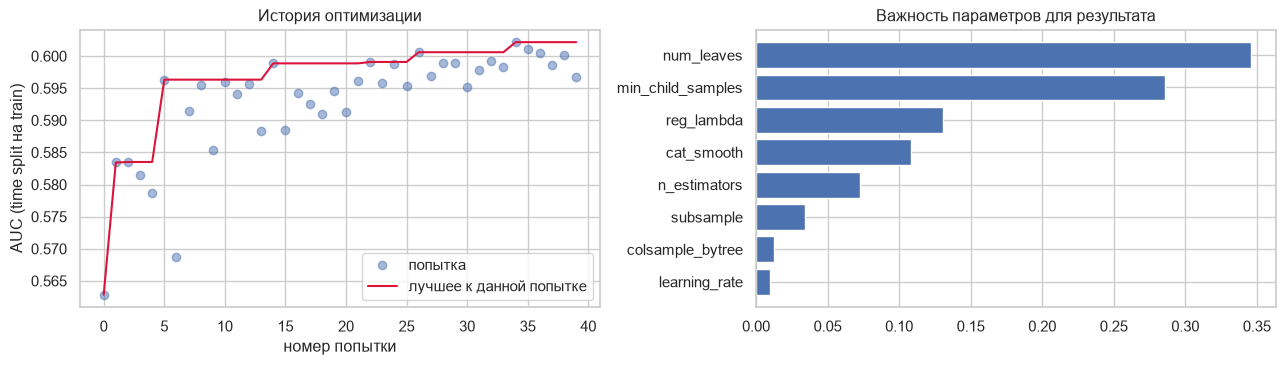

AUC по фолдам time split (train): базовые параметры [0.526, 0.531, 0.542, 0.598, 0.641] -> среднее 0.5677
                                  подобранные          [0.569, 0.58, 0.573, 0.629, 0.66] -> среднее 0.6022


In [24]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
v = [t.value for t in study.trials]; ax[0].plot(v, 'o', alpha=.5, label='попытка'); ax[0].plot(np.maximum.accumulate(v), color='crimson', label='лучшее к данной попытке')
ax[0].set(xlabel='номер попытки', ylabel='AUC (time split на train)', title='История оптимизации'); ax[0].legend()
imp = pd.Series(optuna.importance.get_param_importances(study)).sort_values(); ax[1].barh(imp.index, imp.values, color='#4c72b0'); ax[1].set(title='Важность параметров для результата')
plt.tight_layout(); plt.show()
base_cv = run_cv(lambda F: mk(), Xt, ytr, sp_in)[0].auc; tuned_cv = run_cv(lambda F: mk(**best), Xt, ytr, sp_in)[0].auc
print('AUC по фолдам time split (train): базовые параметры', base_cv.round(3).tolist(), f'-> среднее {base_cv.mean():.4f}')
print('                                  подобранные         ', tuned_cv.round(3).tolist(), f'-> среднее {tuned_cv.mean():.4f}')

**Вывод раздела 6.** Optuna нашла очень «скромную» модель: всего 3 листа в дереве, малый шаг обучения 0,017, сильная регуляризация. Алгоритм сам пришёл к выводу, что сигнал слабый и сложная модель переобучится. Выигрыш на train-фолдах велик (AUC 0,568 → 0,602), но он **частично получен подгонкой**: параметры выбирались именно по этим фолдам. Честную оценку даёт hold-out (раздел 7.1): там выигрыш от настройки заметно меньше (AUC 0,592 → 0,600). Именно поэтому мы смотрим на hold-out, а не на лучший результат подбора.

# 7. Финальная модель и оценка на hold-out

Здесь мы впервые обращаемся к отложенной выборке (2009-06 … 2010-11). Модель с параметрами из раздела 6 обучается на train и предсказывает hold-out.

## 7.1 Итоговые метрики и вклад решений

In [25]:
def metrics(yt_, p_, f=0.10):
    k = int(len(yt_) * f); idx = np.argsort(-p_)[:k]
    return {'AUC': roc_auc_score(yt_, p_), 'PR-AUC': average_precision_score(yt_, p_), 'Precision@10%': yt_[idx].mean(), 'Lift@10%': yt_[idx].mean() / yt_.mean()}
def boot(yt_, p_, B=300, seed=0):
    r = np.random.default_rng(seed); A, L = [], []
    for _ in range(B):
        i = r.integers(0, len(yt_), len(yt_)); A.append(roc_auc_score(yt_[i], p_[i])); k = int(len(i) * .1); L.append(yt_[i][np.argsort(-p_[i])[:k]].mean() / yt_[i].mean())
    return np.percentile(A, [2.5, 97.5]), np.percentile(L, [2.5, 97.5])
def fit_pred(F, prm): return mk(**prm).fit(F.iloc[tr], y[tr]).predict_proba(F.iloc[te])[:, 1]

variants = {'ФИНАЛЬНАЯ МОДЕЛЬ': (X, best), 'то же, но параметры по умолчанию (BASE)': (X, {}), 'без истории клиента': (base_nh, best),
            'с campaign (без истории)': (with_campaign, best), 'с признаками периода month/day/contact': (with_proxy, best),
            'с duration (утечка)': (X.assign(duration=raw.duration.values), best)}
P, rows = {}, []
for name, (F, prm) in variants.items():
    P[name] = fit_pred(F, prm); rows.append({'вариант': name, **metrics(yte, P[name])})
for name in ['Логистическая регрессия', 'CatBoost']:      # другие семейства на тех же признаках, для сравнения
    P[name + ' (для сравнения)'] = models[name](X).fit(X.iloc[tr], y[tr]).predict_proba(X.iloc[te])[:, 1]; rows.append({'вариант': name + ' (для сравнения)', **metrics(yte, P[name + ' (для сравнения)'])})
res = pd.DataFrame(rows).set_index('вариант'); display(res.round(3))
p = P['ФИНАЛЬНАЯ МОДЕЛЬ']; ci_a, ci_l = boot(yte, p)
print(f'ФИНАЛ: AUC {roc_auc_score(yte, p):.3f} (95% ДИ {ci_a[0]:.3f}–{ci_a[1]:.3f}); Lift@10% {metrics(yte, p)["Lift@10%"]:.2f} (95% ДИ {ci_l[0]:.2f}–{ci_l[1]:.2f})')
print(f'базовая конверсия на hold-out {yte.mean():.1%}; максимально возможный Lift@10% = {1 / yte.mean():.2f}')

,AUC,PR-AUC,Precision@10%,Lift@10%
вариант,,,,
ФИНАЛЬНАЯ МОДЕЛЬ,0.600,0.554,0.666,1.463
"то же, но параметры по умолчанию (BASE)",0.592,0.546,0.609,1.338
без истории клиента,0.594,0.547,0.624,1.370
с campaign (без истории),0.594,0.550,0.622,1.366
с признаками периода month/day/contact,0.638,0.588,0.673,1.479
с duration (утечка),0.697,0.620,0.706,1.551
Логистическая регрессия (для сравнения),0.614,0.586,0.727,1.596
CatBoost (для сравнения),0.602,0.564,0.655,1.438


ФИНАЛ: AUC 0.600 (95% ДИ 0.583–0.614); Lift@10% 1.46 (95% ДИ 1.37–1.55)
базовая конверсия на hold-out 45.5%; максимально возможный Lift@10% = 2.20


**Вывод 7.1.**
- Финальная модель: **AUC 0,600** (95% ДИ 0,583–0,614), **Lift@10% = 1,46** (1,37–1,55) при максимально возможном 2,20 для такой базовой конверсии. В топ-10% по модели доля согласившихся 67% против 45,5% в среднем.
- **Настройка параметров дала малый, но реальный прирост** (0,592 → 0,600). История клиента (+0,006) и удаление `campaign` дают разницу в пределах шума.
- **Утечка `duration` видна и здесь** (AUC 0,70): тот же эффект, что в H1.
- **Другие семейства.** Логистическая регрессия на тех же признаках на hold-out получилась даже чуть лучше LightGBM (AUC 0,614, Lift@10% 1,60, Precision@10% 73%), CatBoost почти равен ему (0,602). Разница между регрессией и LightGBM (0,014) сопоставима с половиной ширины доверительного интервала (≈0,015), поэтому утверждать превосходство регрессии нельзя, но и **сложная модель простую не превосходит**. LightGBM остаётся финальной моделью, потому что был выбран на train до обращения к hold-out; логистическую регрессию стоит держать как простой и не менее сильный эталон.
- **Признаки периода (`month`, `day`, `contact`) на hold-out помогают** (0,638 против 0,600). Это противоречит выводу H2 по блочной проверке, мы разбираем это в диагностике ниже.

### Диагностика: какие именно признаки периода дают прирост на hold-out
В таблице выше модель с `month` / `day` / `contact` оказалась на hold-out лучше финальной. Решение убрать эти признаки принималось по train (раздел 4, H2), и менять его по результату на hold-out нельзя: иначе hold-out перестанет быть независимой проверкой. Но результат нужно понять, поэтому ниже диагностика: добавляем признаки по одному. Это **не выбор модели**, а попытка объяснить расхождение.

In [26]:
full = build(raw, drop=['campaign', 'campaign_clip'])
rows = [{'добавлено к финальному набору': 'ничего (финал)', 'AUC на hold-out': roc_auc_score(yte, p)}]
for nm, cols in [('month', ['month', 'month_num']), ('day', ['day']), ('contact', ['contact', 'contact_unknown']), ('все прокси периода', ['month', 'month_num', 'day', 'contact', 'contact_unknown'])]:
    rows.append({'добавлено к финальному набору': nm, 'AUC на hold-out': roc_auc_score(yte, fit_pred(pd.concat([X, full[cols]], axis=1), best))})
display(pd.DataFrame(rows).set_index('добавлено к финальному набору').round(3))
mo = pd.DataFrame({'период': per['период'].values, 'y': y}).iloc[te].groupby('период').y.agg(['size', 'mean']).rename(columns={'size': 'строк', 'mean': 'конверсия'})
print('конверсия по месяцам внутри hold-out (видно, что база сама сильно меняется):'); display(mo.round(2).T)

,AUC на hold-out
добавлено к финальному набору,
ничего (финал),0.600
month,0.634
day,0.598
contact,0.614
все прокси периода,0.643


конверсия по месяцам внутри hold-out (видно, что база сама сильно меняется):


период,2009-06,2009-07,2009-08,2009-09,2009-10,2009-11,2009-12,2010-01,2010-02,2010-03,2010-04,2010-05,2010-06,2010-07,2010-08,2010-09,2010-10,2010-11
строк,642.00,207.00,772.00,282.00,438.00,297.00,201.00,227.00,353.00,219.00,214.00,234.00,213.00,308.00,260.00,297.00,220.00,75.00
конверсия,0.38,0.37,0.34,0.44,0.42,0.49,0.49,0.46,0.53,0.56,0.59,0.57,0.49,0.54,0.52,0.49,0.41,0.48


**Вывод диагностики.** Прирост на hold-out почти целиком даёт `month` (+0,03 AUC); `contact` даёт меньше, `day` ничего. Это можно объяснить двумя способами, и по данным их не различить:
1. **Настоящая сезонность.** Если в банке есть сезонные кампании (весной и осенью конверсия выше), то месяц несёт реальный сигнал.
2. **Разделение подпериодов внутри hold-out.** Конверсия внутри самой отложенной выборки сильно меняется по месяцам (таблица выше), а AUC считается по всему окну. Признак `month` помогает «угадать», в каком подпериоде находится звонок, и получает кредит за различие базовых уровней, а не за различие клиентов.

**Как мы поступаем.** Решение убрать признаки периода было принято по train (блочная проверка: минус 0,03 AUC) до того, как мы увидели hold-out, и мы его не меняем: иначе hold-out перестал бы быть независимой проверкой. Но результат нужно считать **открытым вопросом**: если у заказчика есть основания считать сезонность устойчивой (например, плановые кампании по месяцам), `month` стоит вернуть и перепроверить на более длинной истории (хотя бы 2–3 полных года, у нас в данных чистых полных лет нет).

## 7.2 PR-кривая, Precision и Lift по доле клиентов
PR-кривая показывает компромисс между точностью (какая доля обзвоненных купит) и полнотой (какую долю всех будущих покупателей мы охватили). Для маркетинга важнее всего начало кривой: что будет, если звонить только верхушке списка.

,Precision,Lift,Recall
топ 2%,0.706,1.551,0.031
топ 5%,0.680,1.494,0.074
топ 10%,0.666,1.463,0.146
топ 20%,0.577,1.268,0.253
топ 30%,0.555,1.219,0.366
топ 50%,0.533,1.170,0.585


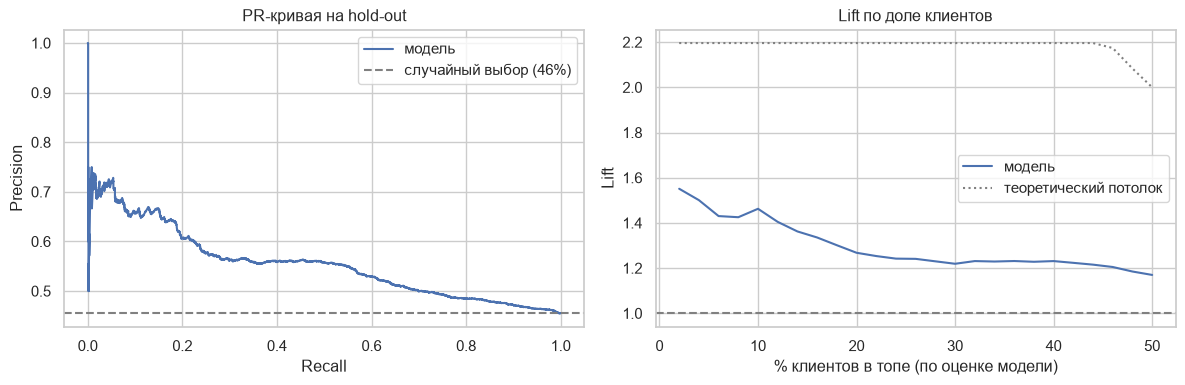

In [27]:
order = np.argsort(-p); fr = [0.02, 0.05, 0.10, 0.20, 0.30, 0.50]
tab = pd.DataFrame({f'топ {int(f * 100)}%': {'Precision': yte[order[:int(len(yte) * f)]].mean(), 'Lift': yte[order[:int(len(yte) * f)]].mean() / yte.mean(),
                                            'Recall': yte[order[:int(len(yte) * f)]].sum() / yte.sum()} for f in fr}).T
display(tab.round(3))
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
pr_, rc_, _ = precision_recall_curve(yte, p); ax[0].plot(rc_, pr_, label='модель'); ax[0].axhline(yte.mean(), ls='--', color='gray', label=f'случайный выбор ({yte.mean():.0%})')
ax[0].set(xlabel='Recall', ylabel='Precision', title='PR-кривая на hold-out'); ax[0].legend()
g = np.linspace(0.02, 0.5, 25); ax[1].plot(g * 100, [yte[order[:int(len(yte) * f)]].mean() / yte.mean() for f in g], label='модель')
ax[1].plot(g * 100, [min(1 / yte.mean(), 1 / f) for f in g], ls=':', color='gray', label='теоретический потолок'); ax[1].axhline(1, ls='--', color='gray')
ax[1].set(xlabel='% клиентов в топе (по оценке модели)', ylabel='Lift', title='Lift по доле клиентов'); ax[1].legend(); plt.tight_layout(); plt.show()

## 7.3 Качество по сегментам: клиенты с историей и без
Общее число скрывает важное различие: модель может хорошо работать на одной группе и совсем не работать на другой.

In [28]:
rows = []
for name, mm in [('есть история', hist_flag[te]), ('нет истории (холодный обзвон)', ~hist_flag[te])]:
    rows.append({'сегмент': name, 'строк': int(mm.sum()), 'доля yes': yte[mm].mean(), **metrics(yte[mm], p[mm])})
seg = pd.DataFrame(rows).set_index('сегмент'); display(seg.round(3))

,строк,доля yes,AUC,PR-AUC,Precision@10%,Lift@10%
сегмент,,,,,,
есть история,2488,0.525,0.657,0.646,0.685,1.307
нет истории (холодный обзвон),2971,0.398,0.512,0.401,0.394,0.991


## 7.4 Как модель разделяет классы
Распределение оценок модели отдельно для «yes» и «no» (анализ через призму целевых классов): чем меньше перекрытие, тем лучше разделение.

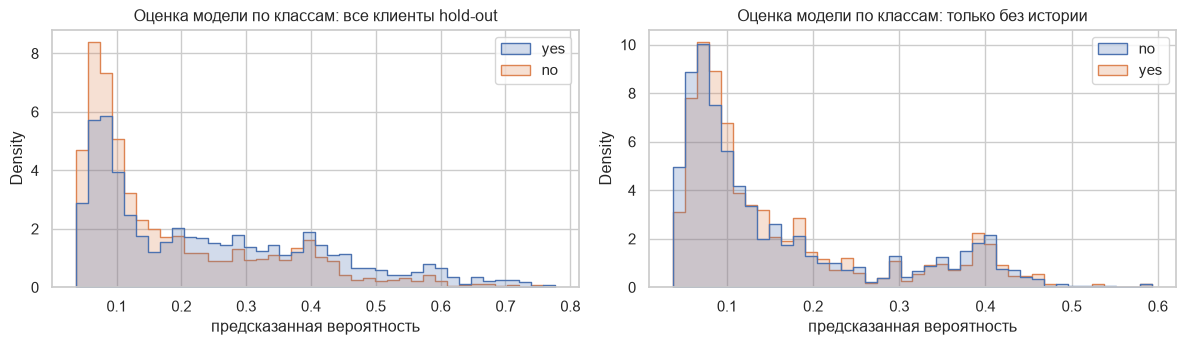

In [29]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
for k, (name, mm) in enumerate([('все клиенты hold-out', np.ones(len(te), bool)), ('только без истории', ~hist_flag[te])]):
    sns.histplot(x=p[mm], hue=np.where(yte[mm] == 1, 'yes', 'no'), bins=40, stat='density', common_norm=False, element='step', ax=ax[k])
    ax[k].set(title=f'Оценка модели по классам: {name}', xlabel='предсказанная вероятность')
plt.tight_layout(); plt.show()

## 7.5 Какие признаки работают
Два взгляда: **gain-важность** (насколько признак улучшал разбиения деревьев при обучении) и **permutation importance** (на сколько падает AUC на hold-out, если случайно перемешать признак). Второй честнее: он показывает вклад на новых данных.

,"gain, доля",падение AUC при перемешивании
h_days_since_buy,0.1163,0.0440
prev_success,0.0250,0.0073
h_n_buys,0.0291,0.0070
h_ever_bought,0.0258,0.0063
balance,0.0816,0.0025
marital,0.0949,0.0023
n_loans,0.1066,0.0023
balance_log,0.0484,0.0011
pdays_clean,0.0685,0.0008
education,0.0376,0.0008


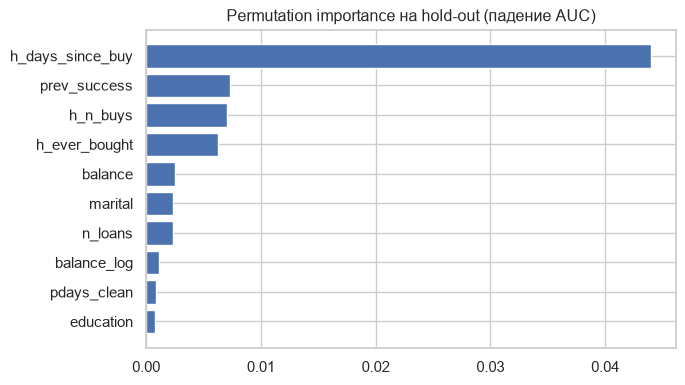

In [30]:
mf = mk(**best, importance_type='gain').fit(X.iloc[tr], y[tr])
gain = pd.Series(mf.feature_importances_, X.columns); gain = (gain / gain.sum())
pi = permutation_importance(mf, X.iloc[te], yte, scoring='roc_auc', n_repeats=5, random_state=SEED, n_jobs=1)
imp = pd.DataFrame({'gain, доля': gain, 'падение AUC при перемешивании': pi.importances_mean}).sort_values('падение AUC при перемешивании', ascending=False)
display(imp.head(12).round(4))
fig, ax = plt.subplots(figsize=(7, 4)); t = imp.head(10)['падение AUC при перемешивании'][::-1]; ax.barh(t.index, t.values, color='#4c72b0'); ax.set(title='Permutation importance на hold-out (падение AUC)'); plt.tight_layout(); plt.show()

**Вывод 7.5.** По падению AUC на hold-out с большим отрывом лидирует `h_days_since_buy` (время с последней покупки клиента), затем `prev_success`, `h_n_buys`, `h_ever_bought`: то есть всё, что связано с прошлой историей покупок. Демографические признаки (`balance`, `marital`, `n_loans`) дают вклад на порядок меньше. Это согласуется с сегментным анализом: модель полезна ровно там, где банк уже знает клиента. Обратите внимание: gain-важность (по обучению) и permutation importance (на hold-out) расходятся: `balance`, `marital` и `n_loans` имеют высокий gain, но почти не влияют на hold-out, то есть они подгоняли модель под train, не обобщаясь. Поэтому для выводов опираемся на permutation importance.

## 7.6 Калибровка и дообучение
Модель обучена на периоде, где доля «yes» мала, а работает на периоде, где она велика: вероятности занижены, хотя ранжирование (AUC) от этого не страдает. Проверяем два способа поправить это на «свежем» куске данных: изотоническую калибровку и дообучение модели. Hold-out делим по времени пополам: первая половина играет роль «свежих данных» (калибруем или дообучаем), вторая служит для оценки.

In [31]:
h = len(te) // 2; a, b = te[:h], te[h:]; yb = y[b]; pb = p[h:]
iso = IsotonicRegression(out_of_bounds='clip').fit(p[:h], y[a]); pc = iso.predict(pb)
tr2 = np.concatenate([tr, a]); pr2 = mk(**best).fit(X.iloc[tr2], y[tr2]).predict_proba(X.iloc[b])[:, 1]
rows = [{'вариант': nm, 'AUC': roc_auc_score(yb, q), 'Lift@10%': metrics(yb, q + 1e-9 * pb)['Lift@10%'], 'средний прогноз': q.mean(), 'Brier': brier_score_loss(yb, q)}
        for nm, q in [('модель из train, без калибровки', pb), ('+ изотоническая калибровка по первой половине', pc), ('дообучение на train + первая половина', pr2)]]
display(pd.DataFrame(rows).set_index('вариант').round(3)); print('реальная доля yes во второй половине hold-out:', yb.mean().round(3))

,AUC,Lift@10%,средний прогноз,Brier
вариант,,,,
"модель из train, без калибровки",0.626,1.294,0.230,0.326
+ изотоническая калибровка по первой половине,0.628,1.294,0.418,0.251
дообучение на train + первая половина,0.645,1.430,0.313,0.280


реальная доля yes во второй половине hold-out: 0.515


**Вывод 7.6.** Вероятности занижены почти вдвое (средний прогноз 23% при реальных 51,5%): модель училась на периоде с конверсией 7%. Изотоническая калибровка по свежему куску исправляет шкалу (средний прогноз 42%, Brier 0,326 → 0,251), но ранжирование не меняет (AUC 0,626 → 0,628, Lift без изменений). **Дообучение на свежих данных помогает и ранжированию**: AUC 0,626 → 0,645, Lift@10% 1,29 → 1,43. Практический вывод: в бою модель нужно регулярно переобучать на недавнем окне, а не использовать «заморозку».

## 7.7 Порог, цена ошибок и прибыль
**Зачем.** В бизнесе важна не метрика, а деньги. Две ошибки стоят по-разному: звонок «не тому» (ложное срабатывание) стоит *c* — время оператора; пропущенный покупатель (ложный отказ) — упущенная выгода *r*. Пусть звонок стоит c = 1, а подписка приносит r. Прибыль при обзвоне k клиентов: `r × (число купивших среди них) − c × k`. **Значения r реальны только у заказчика; здесь они иллюстративные**, нас интересует логика и сравнение стратегий.

**Что сравниваем:** «не звонить никому» (прибыль 0), «звонить всем», «звонить верхним f% по модели». Долю f выбираем **не на hold-out** (это подгонка), а на первой половине hold-out, а проверяем на второй: так же поступил бы банк, перенастраивающий порог по свежим данным.

In [32]:
fs = np.linspace(0.02, 1.0, 50)
def profit(yt_, p_, f, r): o = np.argsort(-p_)[:max(1, int(len(yt_) * f))]; return (r * yt_[o].sum() - len(o)) / len(yt_)
rows = []
for r in [1.5, 2.2, 3.0, 5.0]:
    f_best = fs[np.argmax([profit(y[a], p[:h], f, r) for f in fs])]                   # долю f выбираем на первой половине
    rows.append({'r / c': r, 'звонить всем': r * yb.mean() - 1, 'доля обзвона f (выбрана на 1-й половине)': f_best,
                 'прибыль модели на 2-й половине': profit(yb, pb, f_best, r), 'случайный список той же доли': f_best * (r * yb.mean() - 1)})
cost = pd.DataFrame(rows).set_index('r / c'); display(cost.round(3))
print('прибыль в расчёте на одного клиента из списка, в единицах стоимости звонка; точка безубыточности «звонить всем»: r/c =', round(1 / yb.mean(), 2))

,звонить всем,доля обзвона f (выбрана на 1-й половине),прибыль модели на 2-й половине,случайный список той же доли
r / c,,,,
1.5,-0.227,0.02,0.000,-0.005
2.2,0.133,0.10,0.047,0.013
3.0,0.545,0.96,0.548,0.523
5.0,1.575,1.00,1.575,1.575


прибыль в расчёте на одного клиента из списка, в единицах стоимости звонка; точка безубыточности «звонить всем»: r/c = 1.94


**Вывод 7.7.** В новом режиме (доля «yes» 51% во второй половине hold-out) стратегия «звонить всем» выгодна уже при r/c выше 1,94. Поэтому **модель даёт выигрыш только там, где звонок почти не окупается**:
- при r/c = 1,5 (ниже порога безубыточности) модель находит небольшую верхушку (2% списка) и выходит в ноль, вместо убытка при обзвоне всех (−0,23 на клиента);
- при r/c = 2,2 выбранная на первой половине доля 10% даёт прибыль 0,05, а «звонить всем» даёт 0,13: **модель хуже простой стратегии**. Причина в том, что доля, подобранная на первой половине, плохо переносится на вторую, где база ещё выше;
- при r/c ≥ 3 оптимальная доля близка к 100%, и модель практически бесполезна.

Это важный практический вывод: **в режиме с высокой базовой конверсией отбор клиентов по этой модели мало что добавляет**. Значения r/c здесь иллюстративные; реальные нужны от заказчика.

# 8. Итоги

## 8.1 Что мы получили
| | результат |
|---|---|
| Финальная модель | LightGBM (3 листа, 400 деревьев, шаг 0,017), 23 признака |
| Качество на hold-out | AUC 0,60 (ДИ 0,58–0,61), Lift@10% 1,46 (1,37–1,55), Precision@10% 67% |
| Для сравнения: логистическая регрессия на тех же признаках | AUC 0,614, Lift@10% 1,60 |
| Клиенты с историей | AUC 0,66, Lift@10% 1,31 |
| «Холодные» клиенты | AUC 0,51, Lift@10% 0,99 (не лучше случайности) |
| После дообучения на свежих данных | AUC 0,645 (вместо 0,626), Lift@10% 1,43 |

## 8.2 Что мы выяснили о данных и методах
1. **`duration` — утечка**, давала AUC 0,9; исключена. Любой скачок качества на десятки процентов — повод искать утечку.
2. **Случайная кросс-валидация завышает качество** из-за временного дрейфа: до 0,14 AUC для набора с признаками периода (0,715 против 0,575 по блокам) и около 0,06 без них (0,624 против 0,568 по времени). Для таких данных нужна проверка по времени и финальный hold-out из «будущего».
3. **Балансировка классов не нужна** для ранжирования и вредна для калибровки; дисбаланс учитывается порогом и анализом стоимости.
4. **Выбор алгоритма не критичен**: логистическая регрессия, случайный лес, CatBoost, XGBoost, LightGBM дают сопоставимое качество (на hold-out регрессия даже чуть лучше: 0,614 против 0,600); решают признаки и схема проверки. Усложнение модели здесь не окупается.
5. **Повторяющиеся клиенты** есть (28% строк), но качество оценок не искажают.
6. **Подбор гиперпараметров** нашёл простую модель; значительную часть его выигрыша на train давала подгонка под фолды, честный выигрыш на hold-out около +0,008 AUC.

## 8.3 Ограничения (чего нельзя утверждать)
- **Качество скромное.** AUC 0,60 означает слабое ранжирование. Для холодных клиентов модель практически бесполезна.
- **Дрейф.** Конверсия меняется в 10 раз за три года, причина данными не объясняется (возможно, банк изменил режим обзвона или авторы датасета пересэмплировали данные). Что будет в будущем, предсказать нельзя.
- **Открытый вопрос про `month`.** На hold-out он даёт +0,03 AUC; мы не знаем, настоящая это сезонность или артефакт, и не можем проверить без более длинной истории.
- **Узкий hold-out.** 5 459 строк, база внутри него меняется от 34% до 59% по месяцам; AUC по такому окну частично отражает различие подпериодов.
- **Связки клиентов приблизительные**: восстановлены по профилю, а не по реальному идентификатору.
- **Стоимости звонка и подписки** в разделе 7.7 иллюстративные.

## 8.4 Рекомендации
1. **Использовать модель в основном для клиентов с историей**; для холодного обзвона нужны другие данные (поведенческие, транзакционные).
2. **Регулярно переобучать** на скользящем окне, включая недавние месяцы, и калибровать вероятности на свежем куске.
3. **Выяснить причину дрейфа** (как собирались данные, менялся ли режим обзвона): от этого зависит, что ждать в бою.
4. **Получить реальные стоимости** звонка и подписки для выбора порога.
5. **Перепроверить `month`** на более длинной истории.
6. **Держать логистическую регрессию как эталон**: она проще, быстрее и на этих данных не слабее бустинга; перейти на бустинг стоит, только если появятся новые признаки с нелинейными эффектами.